<a href="https://colab.research.google.com/github/kenzy991/oral_disease_imageclassification_CNN/blob/main/OralDisease_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [77]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

kenzyhamdy_oraldisease_path = kagglehub.dataset_download('kenzyhamdy/oraldisease')

print('Data source import complete.')


100%|██████████| 67.4M/67.4M [00:02<00:00, 28.8MB/s]

Extracting files...


Data source import complete.


In [ ]:
import os, re, hashlib, shutil, random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, optimizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv2D,GlobalAveragePooling2D, MaxPooling2D, Dropout, BatchNormalization, Dense, Input, Flatten
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, ResNet50
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Model

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

In [ ]:

import os
zip_path = "/content/Sprint2Data set.zip"
extract_path = "/content/extracted_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed successfully!")

Extraction completed successfully!


In [ ]:
import os

print("Files in extracted_data:", os.listdir("/content/extracted_data"))

Files in extracted_data: ['Sprint2Data set']


In [ ]:
BASE = "/content/extracted_data/Sprint2Data set"

YOLO = BASE + "/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data"
CALC = BASE + "/Calculus/Calculus"
OUT = "/content/data"

SEED = 42

print("YOLO exists:", os.path.exists(YOLO))
print("Calculus exists:", os.path.exists(CALC))

YOLO exists: True
Calculus exists: True


In [ ]:
rows = []

for split in ["train", "val"]:
    img_folder = f"{YOLO}/images/{split}"
    label_folder = f"{YOLO}/labels/{split}"

    for file in os.listdir(img_folder):
        path = os.path.join(img_folder, file)
        name = os.path.splitext(file)[0]
        label_path = os.path.join(label_folder, name + ".txt")

        if os.path.exists(label_path):
            with open(label_path) as f:
                ids = [line.split()[0] for line in f if line.strip()]

            if ids:
                label = {"0": "Caries", "3": "Gingivitis"}.get(ids[0], "check")
            else:
                label = "check"

        elif file.startswith("caries_"):
            label = "Caries"

        elif re.fullmatch(r"\(\d+\)", name):
            label = "Gingivitis"

        else:
            numbers = re.findall(r"\d+", name)
            num = int(numbers[0]) if numbers else -1

            if 3 <= num <= 98 or 200 <= num <= 217:
                label = "Caries"
            elif 218 <= num <= 456:
                label = "Ulcer"
            elif 458 <= num <= 640:
                label = "Tooth Discoloration"
            elif num in [0, 2, 99, 104, 105]:
                label = "Caries"
            else:
                label = "check"

        rows.append([path, label, split])

for file in os.listdir(CALC):
    path = os.path.join(CALC, file)

    if os.path.isfile(path):
        rows.append([path, "Calculus", "calculus"])

df = pd.DataFrame(rows, columns=["path", "label", "source"])

print("Total collected:", len(df))
df.head()

Total collected: 2838


,path,label,source
0,/content/extracted_data/Sprint2Data set/Caries...,Caries,train
1,/content/extracted_data/Sprint2Data set/Caries...,Caries,train
2,/content/extracted_data/Sprint2Data set/Caries...,Caries,train
3,/content/extracted_data/Sprint2Data set/Caries...,Caries,train
4,/content/extracted_data/Sprint2Data set/Caries...,Caries,train


In [ ]:
reject = [28, 92, 231, 457, 472, 516, 578, 580, 598, 620]

def get_number(path):
    numbers = re.findall(r"\d+", os.path.basename(path))
    return int(numbers[0]) if numbers else -1

df["number"] = df["path"].apply(get_number)

# Remove images without a valid label
df = df[
    ~((df["source"] != "calculus") &
      (df["label"] == "check"))
]

# Remove rejected images
df = df[
    ~((df["source"] != "calculus") &
      (df["number"].isin(reject)) &
      (~df["path"].str.contains(r"\(\d+\)\.", regex=True)))
]

df = df.reset_index(drop=True)

print("Images after cleaning:", len(df))
print(df["label"].value_counts())

Images after cleaning: 2828
label
Calculus               1296
Caries                  852
Gingivitis              250
Ulcer                   243
Tooth Discoloration     187
Name: count, dtype: int64


In [ ]:
def md5_file(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df["path"].apply(md5_file)
print("1) before dedup:", len(df), "| unique hashes:", df["hash"].nunique())

yolo_hashes = set(df.loc[df["source"] != "calculus", "hash"])
in_both = df[(df["source"] == "calculus") & (df["hash"].isin(yolo_hashes))]
print("2) Calculus images that also exist in YOLO:", len(in_both))
df = df[~((df["source"] == "calculus") & (df["hash"].isin(yolo_hashes)))]
print("   after removing them:", len(df))


n_labels = df.groupby("hash")["label"].nunique()
bad = n_labels[n_labels > 1].index
print("3) hashes with conflicting labels:", len(bad))
df = df[~df["hash"].isin(bad)]


df = df.drop_duplicates("hash").reset_index(drop=True)
print("4) after drop_duplicates:", len(df))

1) before dedup: 2828 | unique hashes: 2178
2) Calculus images that also exist in YOLO: 102
   after removing them: 2726
3) hashes with conflicting labels: 2
4) after drop_duplicates: 2176


In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 1523
Validation: 326
Test: 327


In [ ]:
if os.path.exists(OUT):
    shutil.rmtree(OUT)

for split, data in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    for i, row in data.iterrows():
        folder = os.path.join(OUT, split, row["label"])
        os.makedirs(folder, exist_ok=True)

        filename = f"{i}_{os.path.basename(row['path'])}"

        shutil.copy2(
            row["path"],
            os.path.join(folder, filename)
        )

print("Dataset saved successfully!")
print("Output path:", OUT)

Dataset saved successfully!
Output path: /content/data


In [ ]:
all_split = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test")
])

print(pd.crosstab(all_split["label"], all_split["split"]))

split                test  train  val
label                                
Calculus              117    547  117
Caries                124    578  124
Gingivitis             27    125   27
Tooth Discoloration    26    119   25
Ulcer                  33    154   33


In [ ]:
for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for label in sorted(os.listdir(os.path.join(OUT, split))):
        folder = os.path.join(OUT, split, label)
        print(label, ":", len(os.listdir(folder)), "images")


TRAIN
Calculus : 547 images
Caries : 578 images
Gingivitis : 125 images
Tooth Discoloration : 119 images
Ulcer : 154 images

VAL
Calculus : 117 images
Caries : 124 images
Gingivitis : 27 images
Tooth Discoloration : 25 images
Ulcer : 33 images

TEST
Calculus : 117 images
Caries : 124 images
Gingivitis : 27 images
Tooth Discoloration : 26 images
Ulcer : 33 images


In [ ]:
SEED = 42
DATA_DIR = "/content/data"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

np.random.seed(SEED)
tf.random.set_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.15),
])

In [ ]:
train_raw = image_dataset_from_directory(
    f"{DATA_DIR}/train",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_raw = image_dataset_from_directory(
    f"{DATA_DIR}/val",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_raw = image_dataset_from_directory(
    f"{DATA_DIR}/test",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_raw.class_names
print(class_names)

Found 1523 files belonging to 5 classes.
Found 326 files belonging to 5 classes.
Found 327 files belonging to 5 classes.
['Calculus', 'Caries', 'Gingivitis', 'Tooth Discoloration', 'Ulcer']


In [ ]:
train_ds = train_raw.map(lambda x, y: (augmentation(x, training=True), y))
train_ds = train_ds.prefetch(AUTOTUNE)

val_ds = val_raw.prefetch(AUTOTUNE)
test_ds = test_raw.prefetch(AUTOTUNE)

images, labels = next(iter(train_ds))
print(images.shape, labels.shape)

(32, 224, 224, 3) (32, 5)


In [ ]:

y_train = []
for i, name in enumerate(class_names):
    n = len(os.listdir(f"{DATA_DIR}/train/{name}"))
    y_train += [i] * n

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=np.array(y_train),
)
class_weights = dict(enumerate(weights))

for i, name in enumerate(class_names):
    print(name, "->", round(class_weights[i], 2))

Calculus -> 0.56
Caries -> 0.53
Gingivitis -> 2.44
Tooth Discoloration -> 2.56
Ulcer -> 1.98


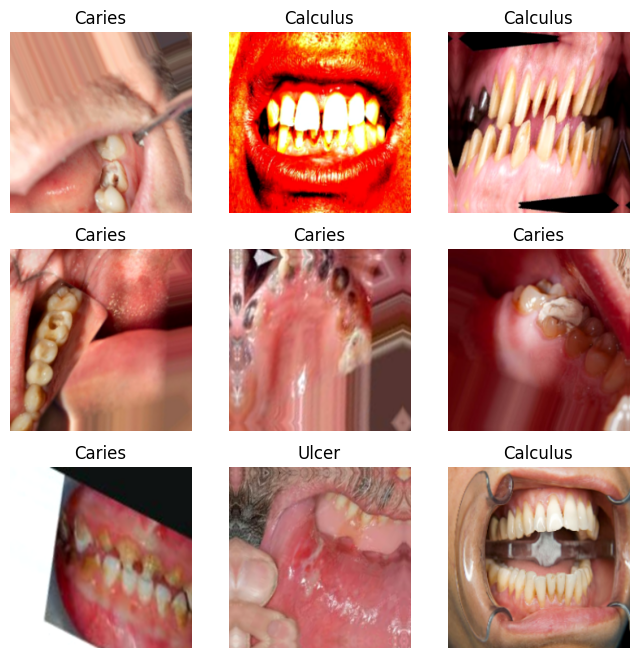

In [ ]:
images, labels = next(iter(train_raw))

plt.figure(figsize=(8, 8))
for i in range(9):
    img = augmentation(tf.expand_dims(images[i], 0), training=True)[0]
    plt.subplot(3, 3, i + 1)
    plt.imshow(tf.clip_by_value(img, 0, 255).numpy().astype("uint8"))
    plt.title(class_names[int(tf.argmax(labels[i]))])
    plt.axis("off")
plt.show()

# # **CustomCNN**

In [ ]:
model = Sequential([
    Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),

    Conv2D(32, 3, padding="same", activation="relu"),
    MaxPooling2D(),

    Conv2D(64, 3, padding="same", activation="relu"),
    MaxPooling2D(),

    Conv2D(128, 3, padding="same", activation="relu"),
    MaxPooling2D(),

    Conv2D(256, 3, padding="same", activation="relu"),
    MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    Dropout(0.4),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(5, activation="softmax"),
], name="custom_cnn")

model.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
reduce_lr  = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
checkpoint = callbacks.ModelCheckpoint("/kaggle/working/custom_cnn_best.keras",
                                       monitor="val_loss", save_best_only=True)
cb_list = [early_stop, reduce_lr, checkpoint]

print("Params:", model.count_params())

Params: 421957


In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
)

checkpoint = callbacks.ModelCheckpoint(
    "/kaggle/working/custom_cnn_best.keras",
    monitor="val_loss",
    save_best_only=True,
)

cb_list = [early_stop, reduce_lr, checkpoint]

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weights,
    callbacks=cb_list,
)

Epoch 1/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 46s 667ms/step - accuracy: 0.3723 - loss: 1.5750 - val_accuracy: 0.5552 - val_loss: 1.3888 - learning_rate: 0.0010
Epoch 2/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 439ms/step - accuracy: 0.3414 - loss: 1.5090 - val_accuracy: 0.4202 - val_loss: 1.3897 - learning_rate: 0.0010
Epoch 3/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 459ms/step - accuracy: 0.4340 - loss: 1.5041 - val_accuracy: 0.5184 - val_loss: 1.5079 - learning_rate: 0.0010
Epoch 4/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 444ms/step - accuracy: 0.4117 - loss: 1.4756 - val_accuracy: 0.5521 - val_loss: 1.4468 - learning_rate: 0.0010
Epoch 5/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 441ms/step - accuracy: 0.4183 - loss: 1.4561 - val_accuracy: 0.4785 - val_loss: 1.3088 - learning_rate: 5.0000e-04
Epoch 6/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 443ms/step - accuracy: 0.4064 - loss: 1.4438 - val_accuracy: 0.4448 - val_loss: 1.2874 - learning_rate: 5.0000e-04
Epoch 7/50
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 450ms/step - accuracy: 0.4051 - 

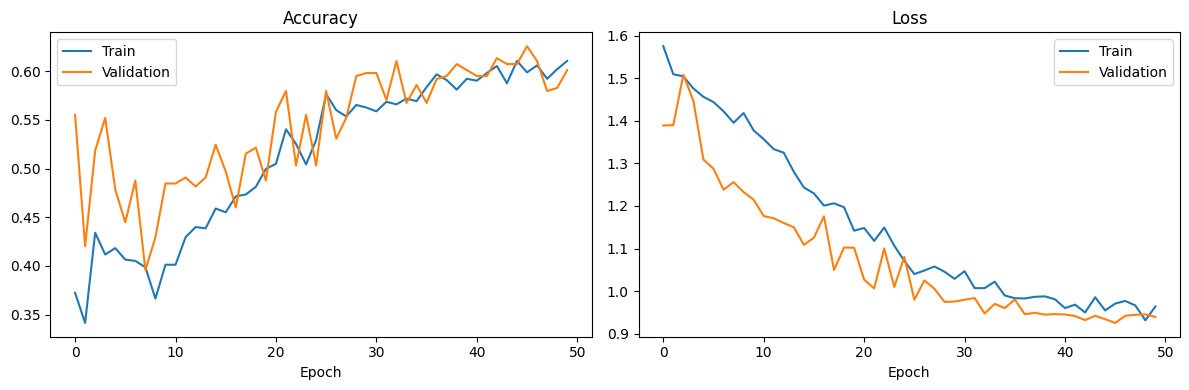

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:

y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in val_ds])
y_pred = model.predict(val_ds, verbose=0).argmax(axis=1)


print(classification_report(y_true, y_pred, target_names=class_names))

                     precision    recall  f1-score   support

           Calculus       0.81      0.84      0.82       117
             Caries       0.78      0.50      0.61       124
         Gingivitis       0.29      0.44      0.35        27
Tooth Discoloration       0.15      0.20      0.17        25
              Ulcer       0.53      0.82      0.64        33

           accuracy                           0.63       326
          macro avg       0.51      0.56      0.52       326
       weighted avg       0.67      0.63      0.63       326



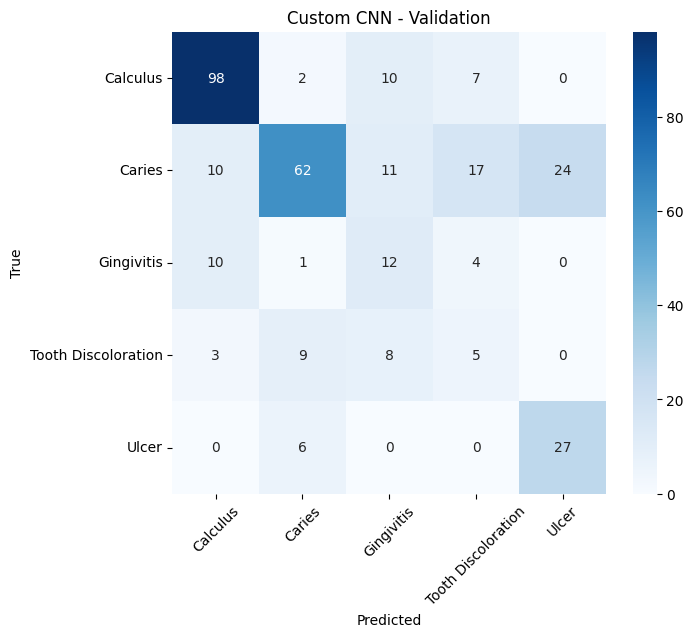

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Custom CNN - Validation")
plt.xticks(rotation=45)
plt.show()

#  **pretrained deep learning models**

# ****MobileNetV2****

In [ ]:
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

base_model.trainable = False
inputs = base_model.input
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(5, activation='softmax')(x)

model_mobilenet = Model(inputs, outputs, name="MobileNetV2_Oral")

model_mobilenet.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_mobilenet = model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=cb_list
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 44s 651ms/step - accuracy: 0.3670 - loss: 1.6393 - val_accuracy: 0.4479 - val_loss: 1.2653 - learning_rate: 0.0010
Epoch 2/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 416ms/step - accuracy: 0.4406 - loss: 1.3402 - val_accuracy: 0.5153 - val_loss: 1.1703 - learning_rate: 0.0010
Epoch 3/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 416ms/step - accuracy: 0.4465 - loss: 1.2731 - val_accuracy: 0.4540 - val_loss: 1.2217 - learning_rate: 0.0010
Epoch 4/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 418ms/step - accuracy: 0.4839 - loss: 1.2118 - val_accuracy: 0.5123 - val_loss: 1.1654 - learning_rate: 5.0000e-04
Epoch 5/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 424ms/step - accuracy: 0.4721 - loss: 1.2197 - val_accuracy: 0.5123 - val_loss: 1.1216 - learning_rate: 5.0000e-04
Epoch 6/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 423ms/step - accuracy: 0.4793 - loss: 1.1949 - val_accuracy: 0.5399 - val_loss: 1.1022 - learning_rate: 5.0000e-04
Epoch 7/25
48/48 ━━━━

# ****EfficientNetB0****

In [ ]:
base_model_eff = EfficientNetB0(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model_eff.trainable = False


inputs_eff = base_model_eff.input
x = base_model_eff(inputs_eff, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs_eff = Dense(5, activation='softmax')(x)

model_eff = Model(inputs_eff, outputs_eff, name="EfficientNetB0_Oral")


model_eff.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


history_eff = model_eff.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=cb_list
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 76s 995ms/step - accuracy: 0.5299 - loss: 1.1312 - val_accuracy: 0.6442 - val_loss: 0.9018 - learning_rate: 0.0010
Epoch 2/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 441ms/step - accuracy: 0.7426 - loss: 0.6901 - val_accuracy: 0.7147 - val_loss: 0.7316 - learning_rate: 0.0010
Epoch 3/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 435ms/step - accuracy: 0.7623 - loss: 0.5967 - val_accuracy: 0.7607 - val_loss: 0.5893 - learning_rate: 0.0010
Epoch 4/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 444ms/step - accuracy: 0.7853 - loss: 0.5507 - val_accuracy: 0.7761 - val_loss: 0.5454 - learning_rate: 0.0010
Epoch 5/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 442ms/step - accuracy: 0.7873 - loss: 0.5127 - val_accuracy: 0.8037 - val_loss: 0.5136 - learning_rate: 0.0010
Epoch 6/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 418ms/step - accuracy: 0.8102 - loss: 0.4878 - val_accuracy: 0.7975 - val_loss: 0.5237 - learning_rate: 0.0010
Epoch 7/25
48/48 ━━━━━━━━━━━━━━

# ****ResNet50****

In [ ]:
base_model_resnet = ResNet50(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model_resnet.trainable = False

inputs_res = base_model_resnet.input
x = base_model_resnet(inputs_res, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs_res = Dense(5, activation='softmax')(x)

model_resnet = Model(inputs_res, outputs_res, name="ResNet50_Oral")

model_resnet.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


history_resnet = model_resnet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=cb_list
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 52s 777ms/step - accuracy: 0.4813 - loss: 1.4515 - val_accuracy: 0.7485 - val_loss: 0.6480 - learning_rate: 0.0010
Epoch 2/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 467ms/step - accuracy: 0.6520 - loss: 0.9235 - val_accuracy: 0.6994 - val_loss: 0.7695 - learning_rate: 0.0010
Epoch 3/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 470ms/step - accuracy: 0.6848 - loss: 0.7892 - val_accuracy: 0.7638 - val_loss: 0.6303 - learning_rate: 0.0010
Epoch 4/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 25s 507ms/step - accuracy: 0.7387 - loss: 0.6675 - val_accuracy: 0.8129 - val_loss: 0.5177 - learning_rate: 5.0000e-04
Epoch 5/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 465ms/step - accuracy: 0.7722 - loss: 0.5753 - val_accuracy: 0.8067 - val_loss: 0.4834 - learning_rate: 5.0000e-04
Epoch 6/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 485ms/step - accuracy: 0.7387 - loss: 0.6282 - val_accuracy: 0.7822 - val_loss: 0.5318 - learning_rate: 5.0000e-04
Epoch 7/25
48/48 ━━

# **Compare between pretrained model**

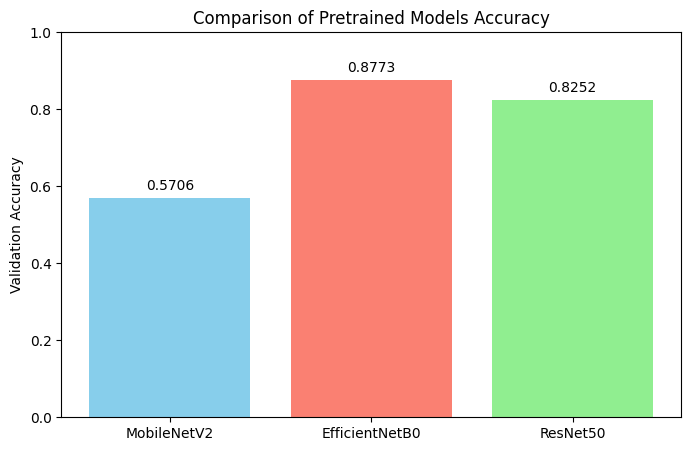

 Best Performing Model is: EfficientNetB0 with Accuracy: 0.8773
Best model saved successfully as 'best_oral_model.h5'!


In [ ]:
models_names = ['MobileNetV2', 'EfficientNetB0', 'ResNet50']

mob_acc = max(history_mobilenet.history['val_accuracy'])
eff_acc = max(history_eff.history['val_accuracy'])
res_acc = max(history_resnet.history['val_accuracy'])

accuracies = [mob_acc, eff_acc, res_acc]

plt.figure(figsize=(8, 5))
plt.bar(models_names, accuracies, color=['skyblue', 'salmon', 'lightgreen'])
plt.ylabel('Validation Accuracy')
plt.title('Comparison of Pretrained Models Accuracy')
plt.ylim(0, 1.0)
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.02, f"{v:.4f}", ha='center')
plt.show()

best_acc_idx = np.argmax(accuracies)
best_model_name = models_names[best_acc_idx]
print(f" Best Performing Model is: {best_model_name} with Accuracy: {accuracies[best_acc_idx]:.4f}")

if best_model_name == 'MobileNetV2':
    model_mobilenet.save('/content/best_oral_model.h5')
elif best_model_name == 'EfficientNetB0':
    model_eff.save('/content/best_oral_model.h5')
else:
    model_resnet.save('/content/best_oral_model.h5')

print("Best model saved successfully as 'best_oral_model.h5'!")

# **Deployment**

In [ ]:
!pip install fastapi uvicorn python-multipart -q

In [ ]:
%%writefile main.py
from fastapi import FastAPI, File, UploadFile
from fastapi.responses import HTMLResponse, JSONResponse
import tensorflow as tf
from PIL import Image, ImageOps
import numpy as np
import io

app = FastAPI()

print("Loading model...")
model = tf.keras.models.load_model('/content/best_oral_model.h5')
class_names = ['Calculus', 'Caries', 'Gingivitis', 'Tooth Discoloration', 'Ulcer']

descriptions = {
    'Calculus': 'Hardened plaque (tartar) on the teeth, usually near the gum line.',
    'Caries': 'Tooth decay: areas where the enamel has been damaged by acid.',
    'Gingivitis': 'Inflamed, red or swollen gums, often caused by plaque build-up.',
    'Tooth Discoloration': 'Teeth that look yellow, brown or stained compared with normal enamel.',
    'Ulcer': 'A sore or open spot on the soft tissue inside the mouth.',
}


HTML_TEMPLATE = """
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>Oral disease classification</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
<link href="https://fonts.googleapis.com/css2?family=Fraunces:opsz,wght@9..144,500;9..144,600&family=Manrope:wght@400;500;600;700&display=swap" rel="stylesheet">
<style>
  :root {
    --paper: #f1f7f6;
    --sheet: #ffffff;
    --ink: #12292d;
    --muted: #5b7378;
    --line: #d3e2df;
    --teal: #0f766e;
    --teal-dark: #0b5953;
    --mist: #e3efed;
    --warn: #b45309;
    --warn-bg: #fdf3e3;
    --err: #b42318;
  }
  * { box-sizing: border-box; margin: 0; padding: 0; }
  html { color-scheme: light; }
  body {
    font-family: 'Manrope', system-ui, sans-serif;
    background: var(--paper);
    color: var(--ink);
    min-height: 100vh;
    line-height: 1.55;
    padding: 28px 20px 40px;
  }
  .wrap { max-width: 1040px; margin: 0 auto; }

  header { display: flex; align-items: center; gap: 10px; margin-bottom: 22px; }
  header .mark {
    width: 34px; height: 34px; border-radius: 10px;
    background: var(--teal); color: #fff;
    display: grid; place-items: center; font-size: 18px;
  }
  header span { font-weight: 700; letter-spacing: .01em; }

  .sheet {
    background: var(--sheet);
    border: 1px solid var(--line);
    border-radius: 22px;
    display: grid;
    grid-template-columns: 1fr 1fr;
    overflow: hidden;
  }
  .pane { padding: 40px; }
  .pane + .pane { border-left: 1px solid var(--line); background: #fafdfc; }

  h1 {
    font-family: 'Fraunces', Georgia, serif;
    font-weight: 600;
    font-size: clamp(30px, 4vw, 42px);
    line-height: 1.1;
    letter-spacing: -.01em;
    margin-bottom: 12px;
  }
  .lead { color: var(--muted); max-width: 40ch; margin-bottom: 28px; }

  .drop {
    position: relative;
    display: grid; place-items: center;
    aspect-ratio: 4 / 3;
    border: 2px dashed #9cc3bd;
    border-radius: 16px;
    background: var(--mist);
    cursor: pointer;
    overflow: hidden;
    text-align: center;
    transition: border-color .2s, background .2s;
  }
  .drop:hover, .drop.over { border-color: var(--teal); background: #d6e9e6; }
  .drop:focus-within { outline: 3px solid var(--teal); outline-offset: 3px; }
  .drop input { position: absolute; inset: 0; opacity: 0; cursor: pointer; }
  .drop .hint { padding: 20px; pointer-events: none; }
  .drop .hint strong { display: block; font-size: 17px; margin: 8px 0 2px; }
  .drop .hint small { color: var(--muted); }
  .drop .hint .icon { font-size: 34px; }
  .drop img {
    position: absolute; inset: 0; width: 100%; height: 100%;
    object-fit: cover; display: none;
  }
  .drop.has-image img { display: block; }
  .drop.has-image .hint { display: none; }

  .actions { display: flex; gap: 10px; margin-top: 16px; }
  button {
    font: inherit; font-weight: 600; cursor: pointer;
    border-radius: 12px; padding: 13px 20px; border: 0;
    transition: background .2s, opacity .2s;
  }
  button:focus-visible { outline: 3px solid var(--teal); outline-offset: 2px; }
  .primary { background: var(--teal); color: #fff; flex: 1; }
  .primary:hover:not(:disabled) { background: var(--teal-dark); }
  .primary:disabled { opacity: .45; cursor: not-allowed; }
  .ghost { background: transparent; color: var(--ink); border: 1px solid var(--line); }
  .ghost:hover { background: var(--mist); }
  .ghost[hidden] { display: none; }

  /* لوحة النتيجة */
  .empty { color: var(--muted); max-width: 34ch; }
  .empty h2 { font-size: 18px; color: var(--ink); margin-bottom: 6px; }

  .loading { display: none; align-items: center; gap: 12px; color: var(--muted); }
  .spinner {
    width: 22px; height: 22px; border-radius: 50%;
    border: 3px solid var(--mist); border-top-color: var(--teal);
    animation: spin .8s linear infinite;
  }
  @keyframes spin { to { transform: rotate(360deg); } }

  .result { display: none; }
  .result .label { color: var(--muted); font-size: 14px; }
  .result .name {
    font-family: 'Fraunces', Georgia, serif;
    font-weight: 600;
    font-size: clamp(34px, 5vw, 50px);
    line-height: 1.05;
    margin: 4px 0 6px;
  }
  .result .conf { font-weight: 700; color: var(--teal); font-size: 18px; }
  .result .desc { color: var(--muted); margin: 14px 0 22px; max-width: 42ch; }

  .notice {
    background: var(--warn-bg); color: var(--warn);
    border-radius: 12px; padding: 12px 14px; font-size: 14px; margin-bottom: 20px;
  }
  .notice[hidden] { display: none; }

  .bars { list-style: none; display: grid; gap: 12px; }
  .bars li { display: grid; grid-template-columns: 1fr auto; gap: 4px 12px; font-size: 14px; }
  .bars .pct { font-variant-numeric: tabular-nums; color: var(--muted); }
  .bars .track {
    grid-column: 1 / -1; height: 8px; border-radius: 99px; background: var(--mist); overflow: hidden;
  }
  .bars .fill { height: 100%; width: 0; background: #9cc3bd; border-radius: 99px; transition: width .7s cubic-bezier(.2,.7,.2,1); }
  .bars li.top .fill { background: var(--teal); }
  .bars li.top .nm { font-weight: 700; }

  .error { display: none; color: var(--err); font-weight: 600; }

  .disclaimer {
    margin-top: 22px; font-size: 12.5px; color: var(--muted); max-width: 60ch;
  }

  @media (max-width: 820px) {
    .sheet { grid-template-columns: 1fr; }
    .pane { padding: 26px 22px; }
    .pane + .pane { border-left: 0; border-top: 1px solid var(--line); }
  }
  @media (prefers-reduced-motion: reduce) {
    .spinner { animation-duration: 2s; }
    .bars .fill { transition: none; }
  }
</style>
</head>
<body>
<div class="wrap">
  <header>
    <div class="mark" aria-hidden="true">🦷</div>
    <span>Oral Disease AI</span>
  </header>

  <main class="sheet">
    <section class="pane">
      <h1>Check a dental photo</h1>
      <p class="lead">Upload a clear, well-lit photo of the teeth or gums and the model will suggest the most likely condition.</p>

      <label class="drop" id="drop">
        <input type="file" id="file" accept="image/*">
        <img id="preview" alt="Selected photo preview">
        <div class="hint">
          <div class="icon" aria-hidden="true">📷</div>
          <strong>Drop a photo here or browse</strong>
          <small>JPG or PNG</small>
        </div>
      </label>

      <div class="actions">
        <button class="primary" id="analyze" disabled>Analyze photo</button>
        <button class="ghost" id="reset" hidden>Choose another</button>
      </div>
    </section>

    <section class="pane" aria-live="polite">
      <div class="empty" id="empty">
        <h2>No result yet</h2>
        <p>Add a photo and select Analyze photo. The result and the model's confidence for each condition will show up here.</p>
      </div>

      <div class="loading" id="loading"><div class="spinner"></div><span>Analyzing photo…</span></div>
      <p class="error" id="error"></p>

      <div class="result" id="result">
        <div class="label">Most likely condition</div>
        <div class="name" id="name"></div>
        <div class="conf" id="conf"></div>
        <p class="desc" id="desc"></p>
        <div class="notice" id="notice" hidden>The model is not very sure about this one. Try a closer, sharper photo with good light.</div>
        <ul class="bars" id="bars"></ul>
      </div>

      <p class="disclaimer">This tool is for screening and learning only. It does not replace an examination by a dentist.</p>
    </section>
  </main>
</div>

<script>
  const $ = (id) => document.getElementById(id);
  const drop = $('drop'), fileInput = $('file'), preview = $('preview');
  const analyzeBtn = $('analyze'), resetBtn = $('reset');
  const emptyEl = $('empty'), loadingEl = $('loading'), errorEl = $('error'), resultEl = $('result');
  let currentFile = null;

  function showOnly(which) {
    emptyEl.style.display = which === 'empty' ? 'block' : 'none';
    loadingEl.style.display = which === 'loading' ? 'flex' : 'none';
    resultEl.style.display = which === 'result' ? 'block' : 'none';
    errorEl.style.display = which === 'error' ? 'block' : 'none';
  }

  function setFile(file) {
    if (!file || !file.type.startsWith('image/')) return;
    currentFile = file;
    preview.src = URL.createObjectURL(file);
    drop.classList.add('has-image');
    analyzeBtn.disabled = false;
    resetBtn.hidden = false;
    showOnly('empty');
  }

  fileInput.addEventListener('change', () => setFile(fileInput.files[0]));

  ['dragenter', 'dragover'].forEach(ev => drop.addEventListener(ev, e => { e.preventDefault(); drop.classList.add('over'); }));
  ['dragleave', 'drop'].forEach(ev => drop.addEventListener(ev, e => { e.preventDefault(); drop.classList.remove('over'); }));
  drop.addEventListener('drop', e => setFile(e.dataTransfer.files[0]));

  resetBtn.addEventListener('click', () => {
    currentFile = null;
    fileInput.value = '';
    preview.removeAttribute('src');
    drop.classList.remove('has-image');
    analyzeBtn.disabled = true;
    resetBtn.hidden = true;
    showOnly('empty');
  });

  analyzeBtn.addEventListener('click', async () => {
    if (!currentFile) return;
    analyzeBtn.disabled = true;
    showOnly('loading');
    try {
      const body = new FormData();
      body.append('file', currentFile);
      const res = await fetch('/predict', { method: 'POST', body });
      const data = await res.json();
      if (!res.ok) throw new Error(data.error || 'Something went wrong.');
      render(data);
    } catch (err) {
      errorEl.textContent = err.message + ' Check the photo and try again.';
      showOnly('error');
    } finally {
      analyzeBtn.disabled = false;
    }
  });

  function render(data) {
    $('name').textContent = data.prediction;
    $('conf').textContent = data.confidence.toFixed(1) + '% confidence';
    $('desc').textContent = data.description;
    $('notice').hidden = data.confidence >= 60;

    const bars = $('bars');
    bars.innerHTML = '';
    data.all.forEach((item, i) => {
      const li = document.createElement('li');
      if (i === 0) li.className = 'top';
      li.innerHTML =
        '<span class="nm"></span><span class="pct">' + item.score.toFixed(1) + '%</span>' +
        '<div class="track"><div class="fill"></div></div>';
      li.querySelector('.nm').textContent = item.label;
      bars.appendChild(li);
      requestAnimationFrame(() => requestAnimationFrame(() => {
        li.querySelector('.fill').style.width = item.score + '%';
      }));
    });
    showOnly('result');
  }

  showOnly('empty');
</script>
</body>
</html>
"""

@app.get("/", response_class=HTMLResponse)
def home():
    return HTML_TEMPLATE

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    contents = await file.read()
    try:
        image = Image.open(io.BytesIO(contents)).convert("RGB")
    except Exception:
        return JSONResponse({"error": "This file could not be read as an image."}, status_code=400)
    size = (224, 224)
    image_resized = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
    img_array = np.asarray(image_resized)
    img_reshape = np.expand_dims(img_array, axis=0)

    probs = model.predict(img_reshape, verbose=0)[0]
    order = np.argsort(probs)[::-1]
    top = int(order[0])

    return {
        "prediction": class_names[top],
        "confidence": float(100 * probs[top]),
        "description": descriptions[class_names[top]],
        "all": [{"label": class_names[int(i)], "score": float(100 * probs[int(i)])} for i in order],
    }

Overwriting main.py


In [75]:
!uvicorn main:app --host 0.0.0.0 --port 8000 & npx localtunnel --port 8000

⠙your url is: https://hot-snails-learn.loca.lt
Loading model...
W0000 00:00:1793205121.452154   26866 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [26866]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     41.234.195.50:0 - "GET / HTTP/1.1" 200 OK
INFO:     41.234.195.50:0 - "GET /favicon.ico HTTP/1.1" 404 Not Found
E0000 00:00:1793205141.519431   26932 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793205141.696838   26932 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
INFO:     41.234.195.50:0 -